## Namn: Ona Kotsolari

### Kurs: Pythonprogrammering och statistisk dataanalys

### Individuell uppgift – Hälsostudie

# Hälsostudie - Del 1

# Setup & Reproducerbarhet

In [2]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt

np.random.seed(42)


df = pd.read_csv("data/health_study_dataset.csv")
display(df.head())
df.info()
print(df.isna().sum())



,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB
id             0
age            0
sex            0
height         0
weight         0
systolic_bp    0
cholesterol    0
smoker         0
disease        0
dtype: int64


#  Beskrivande analys

In [3]:
stats_cols = ["age", "weight", "height", "systolic_bp", "cholesterol"]

df[stats_cols].agg(["mean", "median", "min", "max"])

,age,weight,height,systolic_bp,cholesterol
mean,49.42625,73.413,171.84925,149.178625,4.92915
median,50.00000,73.200,171.35000,149.400000,4.97000
min,18.00000,33.700,144.40000,106.800000,2.50000
max,90.00000,114.400,200.40000,185.900000,7.88000


# Visualiseringar

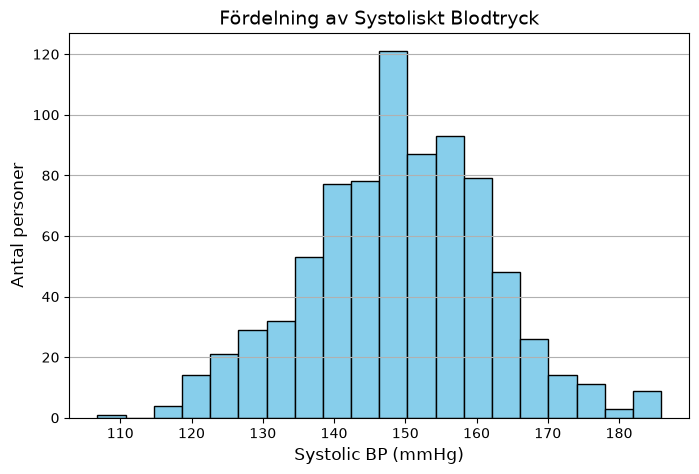

In [4]:
# Skapa ett fönster för grafen 
fig, ax = plt.subplots(figsize=(8, 5))

# Rita ett histogram för systoliskt tryck
ax.hist(df["systolic_bp"], bins=20, color="skyblue", edgecolor="black")

# Titlar och taggar  
ax.set_title("Fördelning av Systoliskt Blodtryck", fontsize=14)
ax.set_xlabel("Systolic BP (mmHg)", fontsize=12)
ax.set_ylabel("Antal personer", fontsize=12)
ax.grid(True,axis="y")

# Visa diagrammet
plt.show()

# Diagram 1: Histogram för systoliskt blodtryck
## (systoliskt bp)

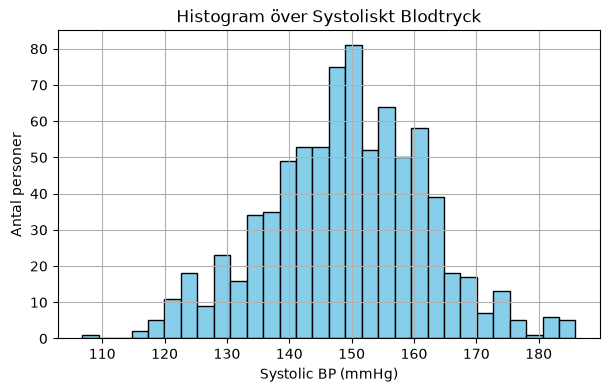

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(df["systolic_bp"], bins=30, color="skyblue", edgecolor="black")
ax.set_title("Histogram över Systoliskt Blodtryck")
ax.set_xlabel("Systolic BP (mmHg)")
ax.set_ylabel("Antal personer")
plt.grid()
plt.show()

# Tolkning
Histogrammet visar fördelningen av det systoliska blodtrycket i datasetet. De flesta observationerna ligger ungefär mellan 140 och 160 mmHg, medan färre personer har mycket låga eller mycket höga värden. Fördelningen är ungefär koncentrerad kring mitten av intervallet.

# Diagram 2: Boxplot för vikt per kön!

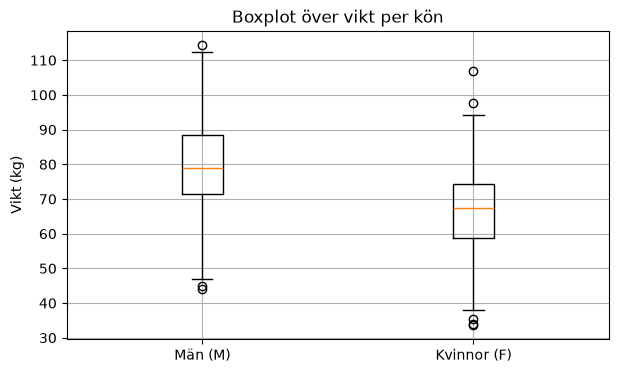

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))

# Vi delar upp vikten efter kön (M och K)
male_weights = df[df["sex"] == "M"]["weight"]
female_weights = df[df["sex"] == "F"]["weight"]

ax.boxplot([male_weights, female_weights], tick_labels=["Män (M)", "Kvinnor (F)"])
ax.set_title("Boxplot över vikt per kön")
ax.set_ylabel("Vikt (kg)")
plt.grid()
plt.show()

# Tolkning:
 Boxploten visar fördelningen av vikt för män och kvinnor. Medianvikten är högre för män än för kvinnor. Diagrammet visar också variationen inom de två grupperna och om det finns observationer som avviker från resten av datan.

# Diagram 3: Stapeldiagram över antal rökare och icke-rökare.

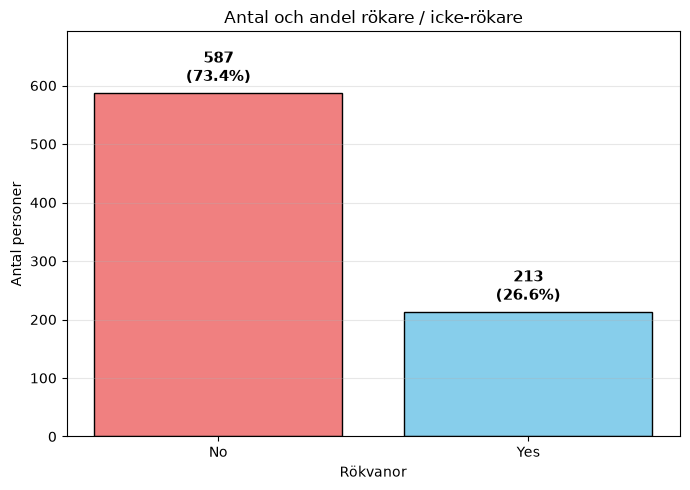

In [22]:
fig, ax = plt.subplots(figsize=(7, 5))

# Räkna antal och andel
smoker_counts = df["smoker"].value_counts()
smoker_props = df["smoker"].value_counts(normalize=True) * 100

bars = ax.bar(smoker_counts.index, smoker_counts.values,
              color=["lightcoral", "skyblue"], edgecolor="black")

ax.set_title("Antal och andel rökare / icke-rökare")
ax.set_xlabel("Rökvanor")
ax.set_ylabel("Antal personer")

# Lägg till antal + procent ovanför varje stapel
for bar, count, prop in zip(bars, smoker_counts.values, smoker_props.values):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height + 12,
            f"{count}\n({prop:.1f}%)",
            ha="center", va="bottom", fontweight="bold", fontsize=11)

# Ge lite mer utrymme upptill så att texten syns tydligt
ax.set_ylim(0, max(smoker_counts.values) * 1.18)

plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Tolkning

Stapeldiagrammet visar både antalet och andelen rökare och icke-rökare i datasetet. 
Det finns betydligt fler icke-rökare (ca 73 %) än rökare (ca 27 %). 

Grupperna är därför olika stora, vilket är viktigt att ta hänsyn till vid jämförelser mellan rökare och icke-rökare (t.ex. vid hypotesprövningen av blodtryck).

# Simulering

In [8]:
# 1. Vi hittar den verkliga sannolikheten för sjukdom från vår datauppsättning
real_disease_prob = df["disease"].mean()
print(f"Verklig andel med sjukdom: {real_disease_prob:.4f} ({real_disease_prob * 100:.2f}%)")

# 2. Vi simulerar 1000 personer baserat på denna sannolikhet (med binomial)
n_simulations = 1000
simulated_disease = np.random.binomial(n=1, p=real_disease_prob, size=n_simulations)

# 3. Vi beräknar det simulerade förhållandet
simulated_prob = simulated_disease.mean()
print(f"Simulerad andel med sjukdom ({n_simulations} personer): {simulated_prob:.4f} ({simulated_prob * 100:.2f}%)")

Verklig andel med sjukdom: 0.0587 (5.88%)
Simulerad andel med sjukdom (1000 personer): 0.0560 (5.60%)


### Simulering av sjukdomsandel

Vi beräknar först den verkliga andelen personer i datasetet som har sjukdomen.  
Därefter simulerar vi 1000 personer med samma sannolikhet för sjukdom (med "numpy.random.binomial") och jämför den simulerade andelen med den verkliga.

# Tolkning och jämförelse

Den verkliga andelen personer med sjukdomen i datasetet är 5,88 % (0.0587).Den simulerade andelen baserat på 1 000 personer blev 5,60 % (0.0560).   

Resultaten ligger mycket nära varandra, vilket visar att simuleringen fungerar som förväntat. Den lilla skillnaden på 0,28 procentenheter beror på den naturliga slumpmässiga variationen som uppstår när man drar ett stickprov på 1 000 personer.   

# Konfidensintervall

I denna del beräknas ett 95 % konfidensintervall för medelvärdet av systolic_bp. Två metoder används:

1. Normalapproximation
2. Bootstrap

Resultaten jämförs för att undersöka om metoderna ger liknande uppskattningar.

### Konfidensintervall - Normalapproximation


Vi beräknar ett 95 % konfidensintervall för medelvärdet av systolic_bp med hjälp av normalapproximation. 

Normalapproximation

- mean
- std
- standard error
- 1.96 × SE



In [9]:
bp = df["systolic_bp"]

mean_bp = bp.mean()
std_bp = bp.std(ddof=1)

n = len(bp)

se = std_bp / np.sqrt(n)

z = 1.96

lower_normal = mean_bp - z * se
upper_normal = mean_bp + z * se

print(f"Mean systolic_bp: {mean_bp:.2f}")
print(f"Normal KI: [{lower_normal:.2f}, {upper_normal:.2f}]")

Mean systolic_bp: 149.18
Normal KI: [148.29, 150.07]


### Tolkning av normalapproximation

Medelvärdet för systolic_bp är 149.18.

Det 95-procentiga konfidensintervallet är [148.29, 150.07].

Detta innebär att det verkliga medelvärdet uppskattas ligga inom detta intervall med 95 % konfidens.


Intervallet är ungefär 1,78 mmHg (150,07–148,29), vilket indikerar en relativt noggrann uppskattning av medelvärdet på grund av urvalsstorleken (n = 800)

### Konfidensintervall - Bootstrap
Vi använder bootstrap för att uppskatta konfidensintervallet utan att anta normalfördelning.

Bootstrap

- 5000 repetitioner
- sample with replacement
- mean
- percentiles 2.5 och 97.5

In [10]:
bootstrap_means = []

for _ in range(5000):
    sample = bp.sample(n=len(bp), replace=True)
    bootstrap_means.append(sample.mean())

lower_boot = np.percentile(bootstrap_means, 2.5)
upper_boot = np.percentile(bootstrap_means, 97.5)

print(f"Bootstrap KI: [{lower_boot:.2f}, {upper_boot:.2f}]")

Bootstrap KI: [148.34, 150.08]


# Histogram Bootstrap

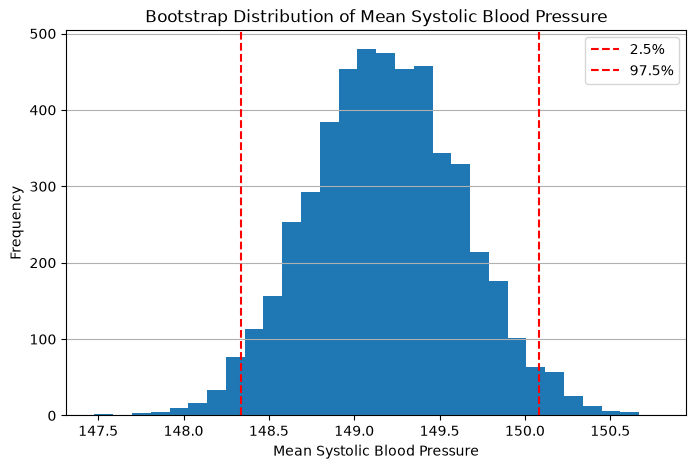

In [11]:

plt.figure(figsize=(8,5))

plt.hist(bootstrap_means, bins=30)

plt.axvline(lower_boot, color="red", linestyle="--", label="2.5%")
plt.axvline(upper_boot, color="red", linestyle="--", label="97.5%")

plt.title("Bootstrap Distribution of Mean Systolic Blood Pressure")
plt.xlabel("Mean Systolic Blood Pressure")
plt.ylabel("Frequency")
plt.grid(True, axis="y")

plt.legend()

plt.show()

### Tolkning av bootstrap

Bootstrap-metoden gav ett 95-procentigt konfidensintervall på [148.33, 150.06].

Intervallet är mycket likt resultatet från normalapproximationen.

## Jämförelse av metoder

Normalapproximationen gav intervallet [148.29, 150.07] medan bootstrap gav intervallet [148.34, 150.08].

Resultaten är nästan identiska, vilket tyder på att uppskattningen av medelvärdet är stabil.

Bootstrap kräver färre antaganden om datafördelningen, medan normalapproximationen bygger på statistiska antaganden om stickprovsfördelningen.

I detta fall leder båda metoderna till samma slutsats.

# Hypotesprövning & Power
 

# Hypotesprövning

- H0: Rökare och icke-rökare har samma genomsnittliga blodtryck.

- H1: Rökare har högre genomsnittligt blodtryck.

In [12]:
from scipy.stats import ttest_ind

smokers = df[df["smoker"] == "Yes"]["systolic_bp"]
non_smokers = df[df["smoker"] == "No"]["systolic_bp"]

t_stat, p_value = ttest_ind(smokers, non_smokers, alternative="greater")

print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_value:.4f}")

print(f"Mean smokers: {smokers.mean():.2f}")
print(f"Mean non-smokers: {non_smokers.mean():.2f}")

T-statistic: 0.4609
P-value: 0.3225
Mean smokers: 149.52
Mean non-smokers: 149.05


In [13]:
print(f"Antal rökare: {len(smokers)}")
print(f"Antal icke-rökare: {len(non_smokers)}")

Antal rökare: 213
Antal icke-rökare: 587


### Resultat och tolkning

Rökare hade ett något högre genomsnittligt systoliskt blodtryck än icke-rökare (149,52 mmHg jämfört med 149,05 mmHg), vilket motsvarar en observerad skillnad på 0,47 mmHg. 

Skillnaden är dock mycket liten i praktiken och inte statistiskt signifikant eftersom p-värdet är 0,3225 (> 0,05).   

Vi kan därför inte förkasta nollhypotesen (H_0) — det finns inte tillräckligt starkt statistiskt stöd i detta dataset för att rökare har högre genomsnittligt blodtryck än icke-rökare. 

Hur väl testet kan upptäcka en sådan liten skillnad undersöks vidare i power-simuleringen nedan.

# Power Simulation

In [14]:
from scipy.stats import ttest_ind

# Vi får de faktiska storlekarna och standardavvikelserna från data
n_smokers = len(smokers)
n_non = len(non_smokers)
mean_diff = smokers.mean() - non_smokers.mean()   # den verkliga skillnaden (~0.47)
std_smokers = smokers.std()
std_non = non_smokers.std()

n_simulations = 1000
significant_results = 0

np.random.seed(42)  # att vara repeterbar 

for _ in range(n_simulations):
    # Vi simulerar data med den "observerade" skillnaden
    sim_smokers = np.random.normal(
        loc=non_smokers.mean() + mean_diff, 
        scale=std_smokers, 
        size=n_smokers
    )
    sim_non = np.random.normal(
        loc=non_smokers.mean(), 
        scale=std_non, 
        size=n_non
    )
    
    _, p_value = ttest_ind(sim_smokers, sim_non, alternative="greater")
    
    if p_value < 0.05:
        significant_results += 1

power = significant_results / n_simulations
print(f"Estimated power (based on observed difference): {power:.3f}")
print(f"Observed mean difference: {mean_diff:.2f}")

Estimated power (based on observed difference): 0.125
Observed mean difference: 0.47


### Tolkning av power-simuleringen

Den uppskattade power blev 0,125 (12,5 %). Det innebär att testet har begränsad förmåga att upptäcka en så liten skillnad mellan grupperna. Den låga powern kan därför vara en möjlig förklaring till att resultatet inte blev statistiskt signifikant.

Resultatet visar också att det är viktigt att tolka ett icke-signifikant resultat med försiktighet, eftersom ett test med låg power kan ha svårt att upptäcka små skillnader.

### Diskussion

- Två metoder användes för att beräkna ett 95 % konfidensintervall för systolic_bp: normalapproximation och bootstrap.  
- Resultaten från metoderna var mycket lika, vilket tyder på att skattningen av medelvärdet är stabil.

- Hypotesprövningen jämförde blodtrycket mellan rökare och icke-rökare med ett ensidigt t-test.  
- P-värdet blev 0.3225, vilket är större än 0.05. Därför kunde nollhypotesen inte förkastas och resultatet gav inget statistiskt stöd för att rökare har högre blodtryck i detta dataset.

- Power-simuleringen baserades på den observerade skillnaden (0.47 mmHg) och de faktiska stickprovsstorlekarna.  
- Den uppskattade power blev endast 0.125 (12,5 %). Det innebär att testet har mycket låg sannolikhet att upptäcka en så liten skillnad, vilket förklarar det icke-signifikanta resultatet.

- Bootstrap valdes också eftersom metoden kräver färre antaganden om normalfördelning än normalapproximationen.

# Del 2


# Linear Regression

In [15]:
from modules.analyzer import HealthAnalyzer

analyzer = HealthAnalyzer(df)


Slope (Age): 0.5360
Intercept: 122.6849
R² Score: 0.3692
RMSE: 10.1549


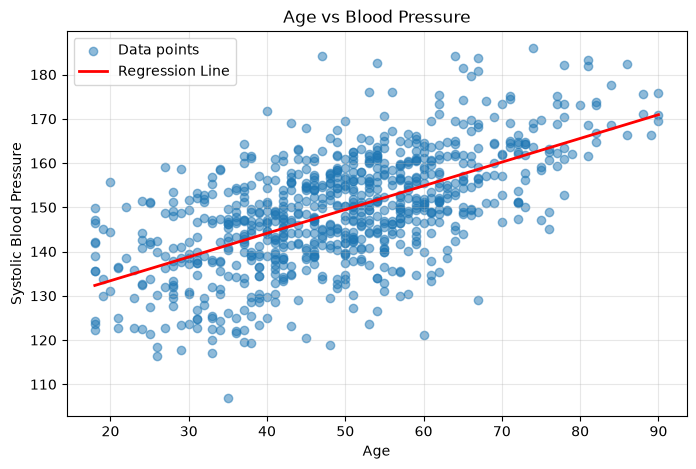

In [16]:

model_simple, r2_simple, rmse_simple = analyzer.linear_regression_age_bp()

print(f"Slope (Age): {model_simple.coef_[0]:.4f}")
print(f"Intercept: {model_simple.intercept_:.4f}")
print(f"R² Score: {r2_simple:.4f}")
print(f"RMSE: {rmse_simple:.4f}")

analyzer.plot_age_bp()

# Tolkning och motivering – Enkel linjär regression
## Resultat och tolkning:

Den enkla linjära regressionen visar en positiv lutning (~0.5360), vilket innebär att det systoliska blodtrycket i genomsnitt ökar med 0,536 mmHg för varje extra år i ålder. Modelens förklaringsgrad är R² Score: 0.3692 (~36.9%),, vilket tyder på att ålder förklarar ungefär 36.8\% av variationen i blodtryck.   

Metodval och motivering :Enkel linjär regression valdes för att etablera en baslinjerelation mellan en enskild kontinuerlig prediktor (age) och utfallsvariabeln (systolic_bp). Eftersom R²-värdet visar att en stor del av variationen fortfarande är oförklarad, motiverar detta användningen av en mer avancerad modell (multipel regression) med fler variabler.   


# Multiple Regression

In [17]:
multi_model, r2_multi, rmse_multi = analyzer.multiple_regression_bp()

features = ["age", "weight", "cholesterol"]
for feature, coef in zip(features, multi_model.coef_):
    print(f"{feature}: {coef:.4f}")

print(f"Intercept: {multi_model.intercept_:.4f}")
print(f"R² Score: {r2_multi:.4f}")
print(f"RMSE: {rmse_multi:.4f}")

age: 0.5264
weight: 0.1706
cholesterol: 0.4315
Intercept: 108.5107
R² Score: 0.4058
RMSE: 9.8553


### Metodval och motivering

Multipel linjär regression valdes eftersom flera variabler kan användas samtidigt för att undersöka sambandet med systoliskt blodtryck. Metoden gör det möjligt att undersöka sambandet mellan systoliskt blodtryck och ålder, vikt och kolesterol samtidigt, samt att kontrollera för de variabler som ingår i modellen.

Det är dock viktigt att komma ihåg att modellen endast tar hänsyn till de variabler som faktiskt ingår i analysen. Resultaten visar samband mellan variablerna och kan inte i sig användas för att dra slutsatser om orsak och verkan.

### Resultat och tolkning - Multipel linjär regression

Modellens resultat visar följande koefficienter:
* Ålder (age): 0,5264 — När åldern ökar med 1 år ökar det systoliska blodtrycket i genomsnitt med 0,53 mmHg, när vikt och kolesterol hålls konstanta.
* Vikt (weight): 0,1706 — När vikten ökar med 1 kg ökar blodtrycket i genomsnitt med 0,17 mmHg, när övriga variabler hålls konstanta.
* Kolesterol (cholesterol): 0,4315 — När kolesterolet ökar med 1 enhet ökar blodtrycket i genomsnitt med 0,43 mmHg, när övriga variabler hålls konstanta.

*Modellens prestanda och jämförelse:*
* Förklaringsgrad (R²): Modellen har ett R²-värde på 0,4058 (40,6 %), vilket är en förbättring jämfört med den enkla linjära regressionen (R² = 0,3692 eller 36,9 %).
* RMSE: Modellanpassningsfelet minskade från 10,1549 till 9,8553, vilket visar att inkluderingen av vikt och kolesterol ger mer precisa förutsägelser.

# PCA (Principal Component Analysis )

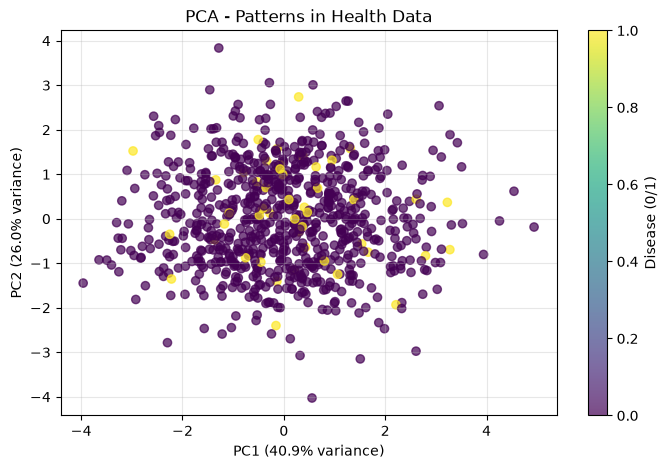

Explained variance ratio per component:
PC1: 0.4091 (40.9%)
PC2: 0.2604 (26.0%)

PCA Loadings (Komponentvikter):


,age,height,weight,systolic_bp,cholesterol
PC1,0.573224,0.098300,0.247196,0.568990,0.526209
PC2,-0.279984,0.693791,0.657227,-0.059119,-0.069424


In [18]:
pca_obj, loadings = analyzer.run_pca()

print("Explained variance ratio per component:")
for i, ratio in enumerate(pca_obj.explained_variance_ratio_):
    print(f"PC{i+1}: {ratio:.4f} ({ratio*100:.1f}%)")

print("\nPCA Loadings (Komponentvikter):")
display(loadings)

# Tolkning och motivering – Principal Component Analysis (PCA)

PCA användes för att undersöka om flera numeriska variabler i datasetet kan sammanfattas i ett mindre antal komponenter. Variablerna standardiserades först så att de får jämförbara skalor.

Komponenter och förklarad varians:

PC1: Förklarar 40,91 % av variansen. Komponenten domineras av höga positiva bidrag från ålder (0,573), systoliskt blodtryck (0,569) och kolesterol (0,526), vilket visar att dessa variabler samvarierar i samma riktning.

PC2: Förklarar 26,04 % av variansen. Komponenten fångar huvudsakligen kroppsstorlek med höga positiva laddningar för längd (0,694) och vikt (0,657).

Tillsammans förklarar de två första komponenterna 66,95 % (cirka 67 %) av den totala variationen i data. PCA ger därmed en förenklad bild av mönstren i datasetet. Det är dock viktigt att komma ihåg att en principal component inte är en direkt medicinsk riskfaktor, utan en statistisk kombination av de ursprungliga variablerna.

# Correlation Heatmap

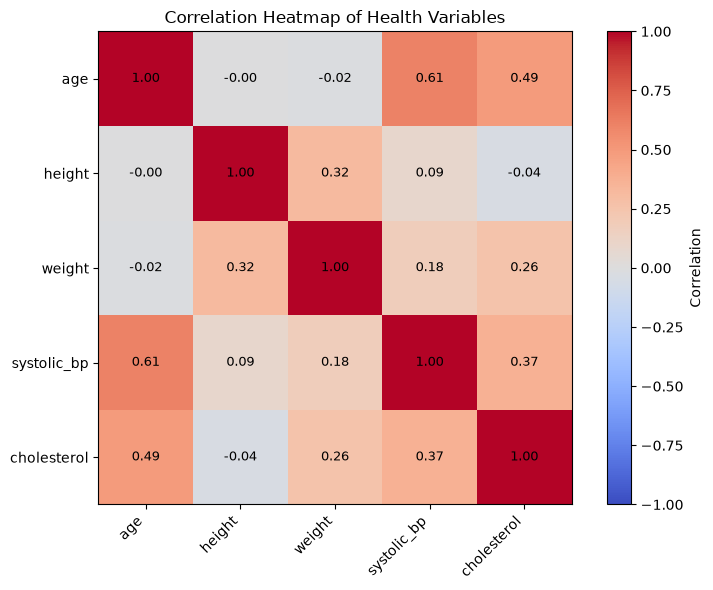

                  age    height    weight  systolic_bp  cholesterol
age          1.000000 -0.004653 -0.017309     0.607578     0.491173
height      -0.004653  1.000000  0.320260     0.086297    -0.043344
weight      -0.017309  0.320260  1.000000     0.179467     0.256214
systolic_bp  0.607578  0.086297  0.179467     1.000000     0.368441
cholesterol  0.491173 -0.043344  0.256214     0.368441     1.000000


In [19]:
# Correlation heatmap
corr_matrix = analyzer.plot_correlation_heatmap()
print(corr_matrix)

### Tolkning

Heatmapen visar korrelationerna mellan de numeriska variablerna i datasetet. En positiv korrelation innebär att högre värden på den ena variabeln tenderar att vara kopplade till högre värden på den andra, medan en negativ korrelation innebär motsatt riktning.

I heatmapen kan man se vilka variabler som har starkare respektive svagare samband med varandra. Korrelationen kan användas för att identifiera mönster och möjliga samband som är värda att undersöka vidare.

Det är viktigt att komma ihåg att korrelation inte innebär kausalitet. Ett starkt samband mellan två variabler betyder därför inte att den ena variabeln orsakar den andra.

Starkast positiv korrelation: Mellan ålder och systoliskt blodtryck (0,6076), samt ålder med kolesterol (0,4912).

Måttlig/svagare korrelation: Mellan längd och vikt (0,3203), och systoliskt blodtryck med kolesterol (0,3684).

Nästan noll eller något negativ korrelation: Såsom ålder med längd (-0,0047) eller längd med kolesterol (-0,0433).

# Residuals Plot

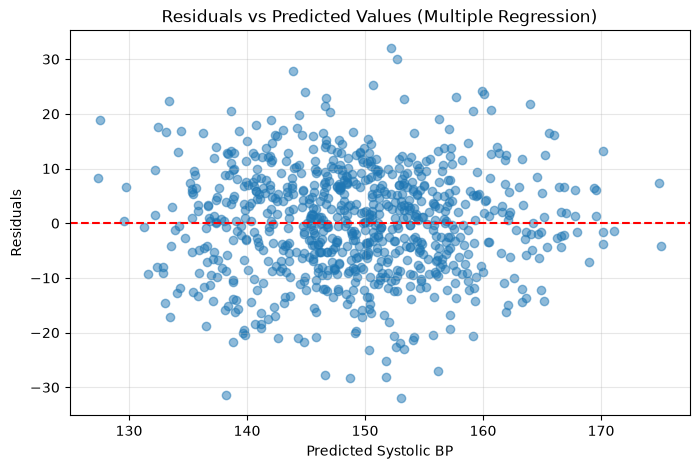

R²: 0.406
RMSE: 9.86


In [20]:
# Residuals plot for multiple regression
analyzer.plot_residuals()

### Resultat

#### Beteende i grafen:

Residualerna är relativt jämnt fördelade runt den horisontella linjen 0 (främst från cirka -25 till +30), utan stark krökning eller en tydlig trattform (heteroscedasticitet), vilket stöder den linjära approximationen.

#### Koppling till modellens prestanda:

Även om det inte finns något starkt systematiskt mönster i residualerna, visar R² (0,406) och RMSE (9,86) att spridningen förblir signifikant, så det finns andra faktorer utanför modellen som påverkar det systoliska trycket.